# EDA + thống kê & xử lý dữ liệu Wine Quality

**Đầu vào:** `data/winequality-red.csv`, `data/winequality-white.csv` (sep=`;`).

**Đầu ra:** `output/wine_clean.csv` (+ bảng và hình trong `output/`), chạy từ thư mục `notebooks/`.

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

os.makedirs("../output", exist_ok=True)

In [2]:
# ------------------------------------------------------------------ đọc & gộp
red = pd.read_csv("../data/winequality-red.csv", sep=";")
white = pd.read_csv("../data/winequality-white.csv", sep=";")
red["wine_type"] = "red"
white["wine_type"] = "white"
wine = pd.concat([red, white], ignore_index=True)
feat_cols = [c for c in wine.columns if c not in ("quality", "wine_type")]


def to_class(q):
    return 0 if q <= 5 else (1 if q == 6 else 2)


label_names = {0: "Thấp (≤5)", 1: "Trung bình (6)", 2: "Cao (≥7)"}
colors = ["#c0392b", "#f39c12", "#27ae60"]


def count_outliers(df):
    """Đếm ngoại lai IQR 1,5, tính riêng từng loại rượu."""
    total = 0
    for _, g in df.groupby("wine_type"):
        for c in feat_cols:
            q1, q3 = g[c].quantile([0.25, 0.75])
            iqr = q3 - q1
            total += int(((g[c] < q1 - 1.5 * iqr) | (g[c] > q3 + 1.5 * iqr)).sum())
    return total

In [3]:
# ================================================================== B. THỐNG KÊ & XỬ LÝ
n_raw = len(wine)
issues = pd.DataFrame({
    "Vấn đề": ["Giá trị thiếu", "Bản ghi trùng", "Ngoại lai (IQR, theo loại rượu)",
               "Dữ liệu sai phạm vi"],
    "Số lượng": [
        int(wine.isnull().sum().sum()),
        int(wine.duplicated().sum()),
        count_outliers(wine),
        int((wine[feat_cols] < 0).sum().sum())
        + int(((wine["pH"] <= 0) | (wine["pH"] >= 14)).sum())
        + int(((wine["alcohol"] <= 0) | (wine["alcohol"] >= 100)).sum())
        + int((wine["free sulfur dioxide"] > wine["total sulfur dioxide"]).sum())
        + int(((wine["quality"] < 0) | (wine["quality"] > 10)).sum()),
    ],
})
print("\n=== B1. Bảng vấn đề dữ liệu ===")
print(issues.to_string(index=False))
issues.to_csv("../output/bang_van_de_du_lieu.csv", index=False)

# Loại trùng, mã hóa wine_type, GIỮ ngoại lai
# Lý do giữ: ngoại lai nằm trong miền hóa lý hợp lý (không âm, không vô lý),
# không phải lỗi nhập liệu; mô hình cây chia theo ngưỡng nên ít bị ảnh hưởng.
wine_clean = wine.drop_duplicates().copy()
wine_clean["wine_type"] = wine_clean["wine_type"].map({"red": 0, "white": 1})

compare = pd.DataFrame({
    "Chỉ tiêu": ["Số mẫu", "Số bản ghi trùng", "Số ngoại lai (IQR)", "Giá trị thiếu"],
    "Trước xử lý": [n_raw, int(wine.duplicated().sum()), count_outliers(wine),
                    int(wine.isnull().sum().sum())],
    "Sau xử lý": [len(wine_clean), int(wine_clean.duplicated().sum()),
                  count_outliers(wine_clean.assign(wine_type=wine_clean["wine_type"])),
                  int(wine_clean.isnull().sum().sum())],
})
print("\n=== B2. So sánh trước – sau xử lý ===")
print(compare.to_string(index=False))
print(f"\nBản ghi trước khi loại trùng: {n_raw} | sau: {len(wine_clean)} "
      f"| đã loại: {n_raw - len(wine_clean)}")
compare.to_csv("../output/so_sanh_truoc_sau.csv", index=False)


=== B1. Bảng vấn đề dữ liệu ===
                         Vấn đề  Số lượng
                  Giá trị thiếu         0
                  Bản ghi trùng      1177
Ngoại lai (IQR, theo loại rượu)      1636
            Dữ liệu sai phạm vi         0

=== B2. So sánh trước – sau xử lý ===
          Chỉ tiêu  Trước xử lý  Sau xử lý
            Số mẫu         6497       5320
  Số bản ghi trùng         1177          0
Số ngoại lai (IQR)         1636       1337
     Giá trị thiếu            0          0

Bản ghi trước khi loại trùng: 6497 | sau: 5320 | đã loại: 1177


In [4]:
# ================================================================== A. EDA
wine_clean["quality_class"] = wine_clean["quality"].apply(to_class)

In [5]:
# A1. Thống kê mô tả
stats = wine_clean[feat_cols].describe().T
stats["skew"] = wine_clean[feat_cols].skew()
print("\n=== A1. Thống kê mô tả ===")
print(stats.round(3).to_string())
stats.round(3).to_csv("../output/thong_ke_mo_ta.csv")


=== A1. Thống kê mô tả ===
                       count     mean     std    min     25%      50%      75%      max   skew
fixed acidity         5320.0    7.215   1.320  3.800   6.400    7.000    7.700   15.900  1.650
volatile acidity      5320.0    0.344   0.168  0.080   0.230    0.300    0.410    1.580  1.505
citric acid           5320.0    0.318   0.147  0.000   0.240    0.310    0.400    1.660  0.484
residual sugar        5320.0    5.048   4.500  0.600   1.800    2.700    7.500   65.800  1.707
chlorides             5320.0    0.057   0.037  0.009   0.038    0.047    0.066    0.611  5.338
free sulfur dioxide   5320.0   30.037  17.805  1.000  16.000   28.000   41.000  289.000  1.363
total sulfur dioxide  5320.0  114.109  56.774  6.000  74.000  116.000  153.250  440.000  0.064
density               5320.0    0.995   0.003  0.987   0.992    0.995    0.997    1.039  0.666
pH                    5320.0    3.225   0.160  2.720   3.110    3.210    3.330    4.010  0.390
sulphates             

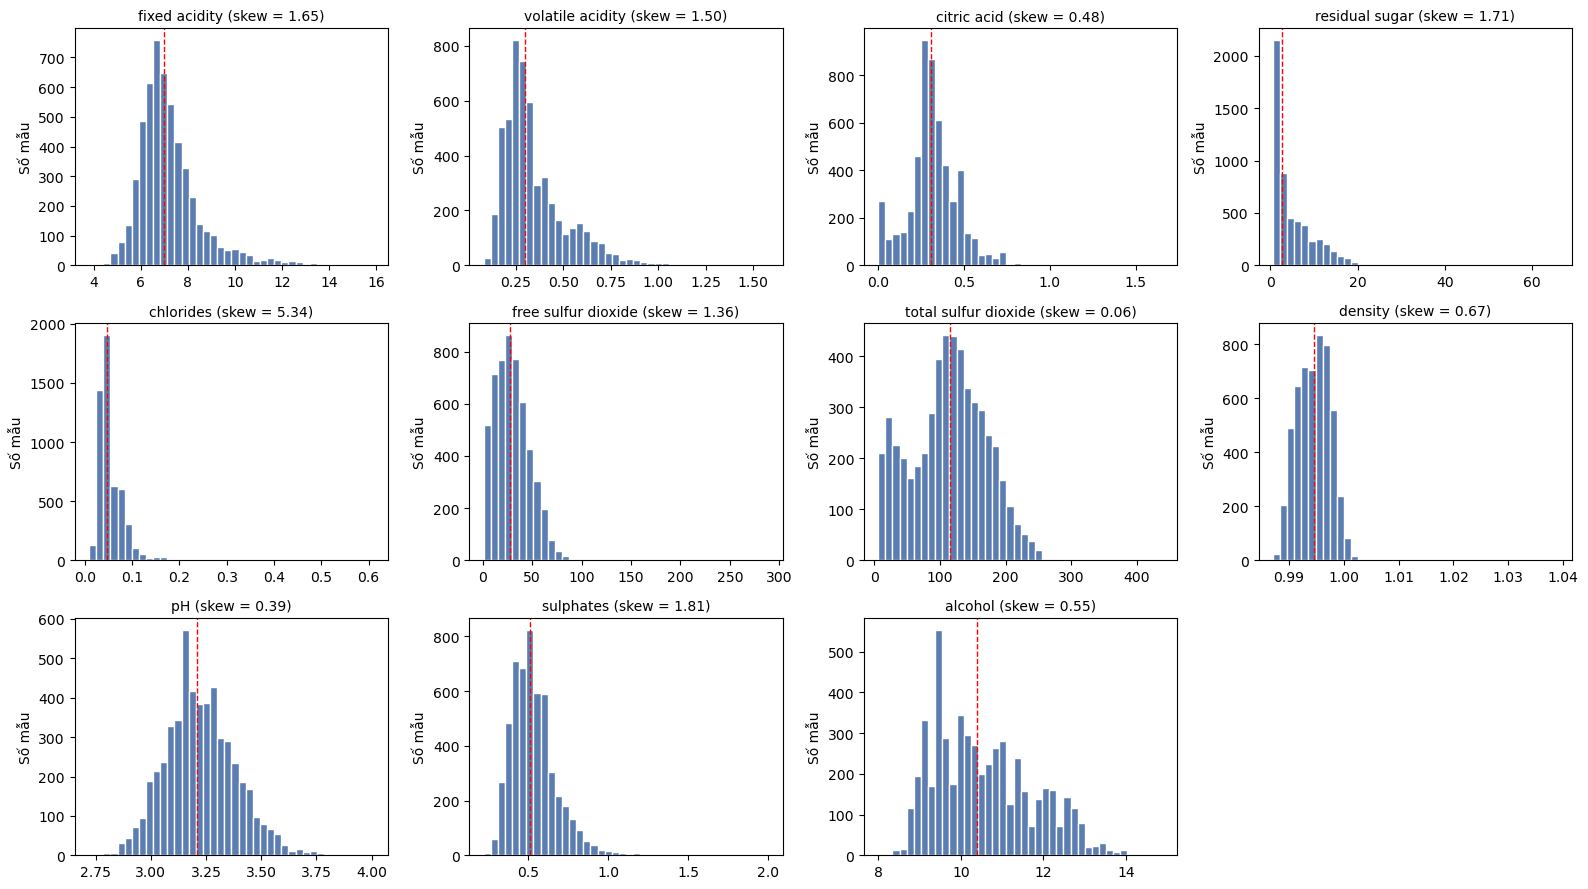

In [6]:
# A2. Phân bố các đặc trưng chính
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), feat_cols):
    ax.hist(wine_clean[c], bins=40, color="#5b7db1", edgecolor="white")
    ax.axvline(wine_clean[c].median(), color="red", ls="--", lw=1)
    ax.set_title(f"{c} (skew = {wine_clean[c].skew():.2f})", fontsize=10)
    ax.set_ylabel("Số mẫu")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig("../output/eda_phan_bo_dac_trung.png", dpi=150)
plt.show()

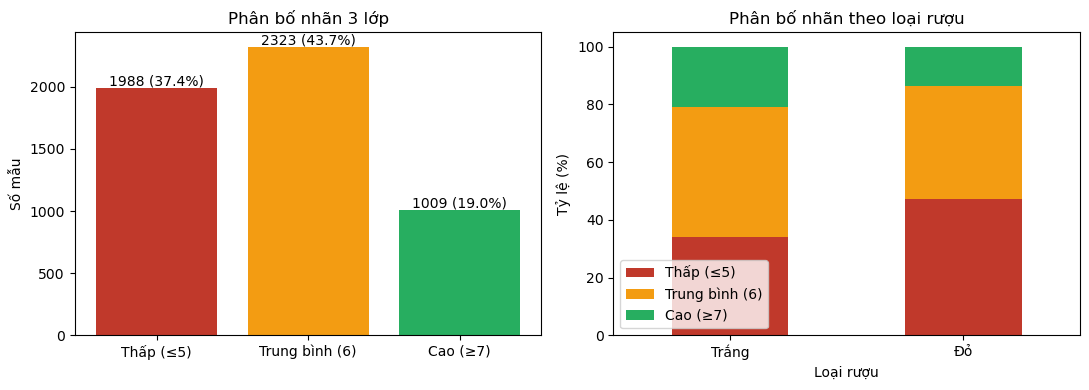

In [7]:
# A3. Phân bố 3 lớp chất lượng (toàn bộ và theo loại rượu)
cnt = wine_clean["quality_class"].value_counts().sort_index()
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar([label_names[i] for i in cnt.index], cnt.values, color=colors)
for i, v in enumerate(cnt.values):
    ax[0].text(i, v + 20, f"{v} ({v / len(wine_clean) * 100:.1f}%)", ha="center")
ax[0].set_ylabel("Số mẫu")
ax[0].set_title("Phân bố nhãn 3 lớp")
by_type = pd.crosstab(wine_clean["wine_type"].map({0: "Đỏ", 1: "Trắng"}),
                      wine_clean["quality_class"], normalize="index") * 100
by_type.columns = [label_names[c] for c in by_type.columns]
by_type.plot(kind="bar", stacked=True, ax=ax[1], color=colors)
ax[1].set_ylabel("Tỷ lệ (%)")
ax[1].set_xlabel("Loại rượu")
ax[1].set_title("Phân bố nhãn theo loại rượu")
ax[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("../output/eda_phan_bo_3_lop.png", dpi=150)
plt.show()

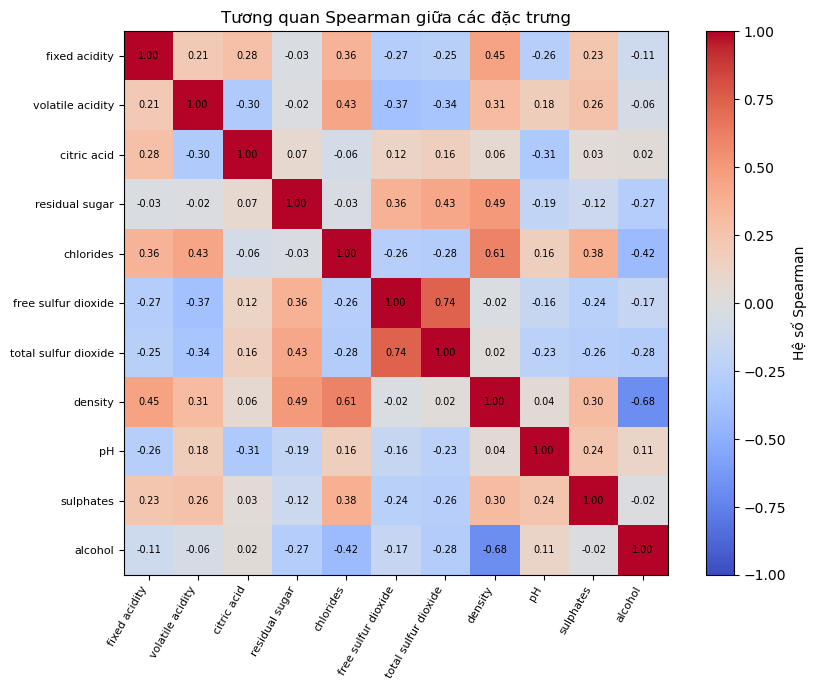

In [8]:
# A4. Ma trận tương quan giữa các đặc trưng (Spearman)
cm = wine_clean[feat_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm.values, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feat_cols)))
ax.set_xticklabels(feat_cols, rotation=60, ha="right", fontsize=8)
ax.set_yticks(range(len(feat_cols)))
ax.set_yticklabels(feat_cols, fontsize=8)
for i in range(len(feat_cols)):
    for j in range(len(feat_cols)):
        ax.text(j, i, f"{cm.values[i, j]:.2f}", ha="center", va="center", fontsize=7)
fig.colorbar(im, label="Hệ số Spearman")
ax.set_title("Tương quan Spearman giữa các đặc trưng")
plt.tight_layout()
plt.savefig("../output/eda_tuong_quan.png", dpi=150)
plt.show()


=== A5. Tương quan Spearman với nhãn ===
alcohol                 0.492
density                -0.358
chlorides              -0.310
volatile acidity       -0.249
citric acid             0.112
fixed acidity          -0.103
free sulfur dioxide     0.073
total sulfur dioxide   -0.069
pH                      0.057
residual sugar         -0.038
sulphates               0.034

Trung vị 4 đặc trưng mạnh nhất theo lớp:
                alcohol  density  chlorides  volatile acidity
quality_class                                                
Cao (≥7)           11.6    0.992      0.038              0.28
Thấp (≤5)           9.7    0.996      0.053              0.34
Trung bình (6)     10.5    0.994      0.046              0.27


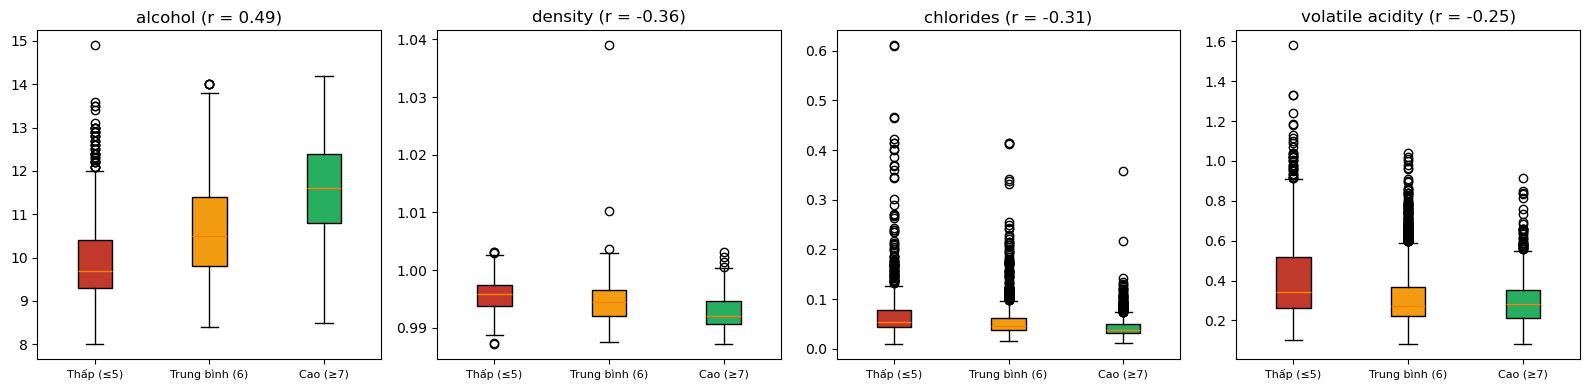


=== Nhận xét ===
1. alcohol liên hệ mạnh nhất với nhãn (r ≈ +0,50): trung vị tăng dần theo lớp chất lượng.
2. density (r ≈ -0,36) chủ yếu là gián tiếp vì tương quan mạnh với alcohol (≈ -0,69)
   và residual sugar; hai đặc trưng chồng lấn thông tin nên cần lưu ý đa cộng tuyến.
3. free và total sulfur dioxide tương quan cao (≈ 0,74); chlorides và volatile acidity
   càng cao thì rượu càng nghiêng về lớp thấp.
4. Không đặc trưng đơn lẻ nào tách được các lớp (các hộp chồng lấn) -> cần mô hình phi tuyến.



In [9]:
# A5. Quan hệ đặc trưng – nhãn
corr_lab = wine_clean[feat_cols].corrwith(wine_clean["quality_class"], method="spearman")
corr_lab = corr_lab.sort_values(key=abs, ascending=False)
print("\n=== A5. Tương quan Spearman với nhãn ===")
print(corr_lab.round(3).to_string())
top4 = corr_lab.index[:4]
print("\nTrung vị 4 đặc trưng mạnh nhất theo lớp:")
print(wine_clean.groupby(wine_clean["quality_class"].map(label_names))[list(top4)]
      .median().round(3).to_string())

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, c in zip(axes, top4):
    data = [wine_clean.loc[wine_clean["quality_class"] == k, c] for k in range(3)]
    bp = ax.boxplot(data, patch_artist=True, tick_labels=[label_names[k] for k in range(3)])
    for patch, col in zip(bp["boxes"], colors):
        patch.set_facecolor(col)
    ax.set_title(f"{c} (r = {corr_lab[c]:.2f})")
    ax.tick_params(axis="x", labelsize=8)
plt.tight_layout()
plt.savefig("../output/eda_dac_trung_vs_nhan.png", dpi=150)
plt.show()

print("""
=== Nhận xét ===
1. alcohol liên hệ mạnh nhất với nhãn (r ≈ +0,50): trung vị tăng dần theo lớp chất lượng.
2. density (r ≈ -0,36) chủ yếu là gián tiếp vì tương quan mạnh với alcohol (≈ -0,69)
   và residual sugar; hai đặc trưng chồng lấn thông tin nên cần lưu ý đa cộng tuyến.
3. free và total sulfur dioxide tương quan cao (≈ 0,74); chlorides và volatile acidity
   càng cao thì rượu càng nghiêng về lớp thấp.
4. Không đặc trưng đơn lẻ nào tách được các lớp (các hộp chồng lấn) -> cần mô hình phi tuyến.
""")

In [10]:
# ------------------------------------------------------------------ XUẤT FILE
out = wine_clean.drop(columns=["quality_class"])  # giữ quality gốc như wine_clean.csv ban đầu
out.to_csv("../output/wine_clean.csv", index=False)
print(f"Đã lưu: output/wine_clean.csv ({out.shape[0]} dòng, {out.shape[1]} cột)")

Đã lưu: output/wine_clean.csv (5320 dòng, 13 cột)
